# Segundo avance — Minería de Datos
## Predicción del riesgo de enfermedad coronaria a 10 años mediante técnicas de minería de datos aplicadas a factores clínicos y de estilo de vida

**Universidad:** Universidad de la Costa  
**Programa:** Ingeniería de Sistemas  
**Asignatura:** Minería de Datos  
**Grupo:** VIRTUAL-25368  
**Docente:** José Escorcia Gutiérrez  
**Estudiante(s):** Escribir aquí los nombres completos de todos los integrantes.

---

## 1. Objetivo

Analizar el conjunto de datos de Framingham, ampliar el análisis exploratorio y entrenar y comparar modelos de clasificación para la variable `TenYearCHD`.

La clase `0` representa los registros sin el evento de enfermedad coronaria registrado durante el horizonte de diez años y la clase `1` los registros con el evento. El modelo es un ejercicio académico y no constituye una herramienta de diagnóstico médico.

**Pregunta del proyecto:** ¿Qué tan bien pueden distintos modelos de clasificación identificar la presencia o ausencia del evento de enfermedad coronaria a diez años a partir de las variables disponibles en el conjunto de datos de Framingham?

## 2. Carga de bibliotecas

Usaremos `pandas` y `numpy` para trabajar con los datos, `matplotlib` y `seaborn` para las visualizaciones y herramientas de `scikit-learn` para preparar, entrenar y evaluar los modelos.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

## 3. Cargar el conjunto de datos

El archivo esperado se llama `framingham.csv`. En Google Colab, si el archivo no está en el entorno, aparecerá la opción para subirlo. Si trabajas localmente, coloca el archivo en la misma carpeta del notebook o ajusta la ruta.

In [2]:
from pathlib import Path

ruta = Path("framingham.csv")

if not ruta.exists():
    try:
        from google.colab import files
        print("Selecciona el archivo framingham.csv")
        archivos = files.upload()
        if "framingham.csv" in archivos:
            ruta = Path("framingham.csv")
        elif len(archivos) == 1:
            nombre_subido = next(iter(archivos))
            ruta = Path(nombre_subido)
        else:
            raise FileNotFoundError(
                "No se encontró framingham.csv entre los archivos subidos. "
                "Verifica el nombre del archivo."
            )
    except ImportError:
        raise FileNotFoundError(
            "No se encontró framingham.csv. Colócalo en la misma carpeta del notebook."
        )

df_original = pd.read_csv(ruta)
df = df_original.copy()

print("Archivo cargado:", ruta)
print("Filas y columnas:", df.shape)
display(df.head())

Selecciona el archivo framingham.csv


Saving framingham.csv to framingham.csv
Archivo cargado: framingham.csv
Filas y columnas: (4240, 16)


,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0


## 4. Descripción inicial y calidad de los datos

Primero revisamos dimensiones, nombres de columnas, tipos de datos, valores faltantes, duplicados y distribución de la variable objetivo. Estas salidas permiten confirmar el estado real del archivo antes de preparar los modelos.

In [3]:
print("Dimensiones:", df.shape)
print("\nColumnas:")
print(df.columns.tolist())

print("\nTipos de datos:")
display(df.dtypes.rename("tipo_de_dato").to_frame())

print("\nValores faltantes por variable:")
faltantes = df.isna().sum().sort_values(ascending=False)
display(faltantes.rename("valores_faltantes").to_frame())

print("\nNúmero de filas duplicadas:", df.duplicated().sum())

if "TenYearCHD" not in df.columns:
    raise ValueError("No se encontró la columna objetivo 'TenYearCHD'. Revisa el archivo.")

print("\nDistribución de TenYearCHD:")
display(
    df["TenYearCHD"]
    .value_counts(dropna=False)
    .rename_axis("TenYearCHD")
    .to_frame("cantidad")
    .assign(porcentaje=lambda x: (x["cantidad"] / len(df) * 100).round(2))
)

Dimensiones: (4240, 16)

Columnas:
['male', 'age', 'education', 'currentSmoker', 'cigsPerDay', 'BPMeds', 'prevalentStroke', 'prevalentHyp', 'diabetes', 'totChol', 'sysBP', 'diaBP', 'BMI', 'heartRate', 'glucose', 'TenYearCHD']

Tipos de datos:


,tipo_de_dato
male,int64
age,int64
education,float64
currentSmoker,int64
cigsPerDay,float64
BPMeds,float64
prevalentStroke,int64
prevalentHyp,int64
diabetes,int64
totChol,float64



Valores faltantes por variable:


,valores_faltantes
glucose,388
education,105
BPMeds,53
totChol,50
cigsPerDay,29
BMI,19
heartRate,1
male,0
prevalentHyp,0
prevalentStroke,0



Número de filas duplicadas: 0

Distribución de TenYearCHD:


,cantidad,porcentaje
TenYearCHD,,
0,3596,84.81
1,644,15.19


### 4.1. Revisión básica de valores

Las siguientes tablas ayudan a detectar valores fuera de los rangos esperados. Un valor extremo no se elimina automáticamente: primero debe revisarse y justificarse cualquier decisión.

In [4]:
display(df.describe(include="all").T)

# Revisar valores distintos en las variables binarias esperadas.
variables_binarias = [
    "male", "currentSmoker", "BPMeds", "prevalentStroke",
    "prevalentHyp", "diabetes", "TenYearCHD"
]
for col in variables_binarias:
    if col in df.columns:
        print(f"{col}: {sorted(df[col].dropna().unique().tolist())}")

,count,mean,std,min,25%,50%,75%,max
male,4240.0,0.429245,0.495027,0.00,0.00,0.0,1.00,1.0
age,4240.0,49.580189,8.572942,32.00,42.00,49.0,56.00,70.0
education,4135.0,1.979444,1.019791,1.00,1.00,2.0,3.00,4.0
currentSmoker,4240.0,0.494104,0.500024,0.00,0.00,0.0,1.00,1.0
cigsPerDay,4211.0,9.005937,11.922462,0.00,0.00,0.0,20.00,70.0
BPMeds,4187.0,0.029615,0.169544,0.00,0.00,0.0,0.00,1.0
prevalentStroke,4240.0,0.005896,0.076569,0.00,0.00,0.0,0.00,1.0
prevalentHyp,4240.0,0.310613,0.462799,0.00,0.00,0.0,1.00,1.0
diabetes,4240.0,0.025708,0.158280,0.00,0.00,0.0,0.00,1.0
totChol,4190.0,236.699523,44.591284,107.00,206.00,234.0,263.00,696.0


male: [0, 1]
currentSmoker: [0, 1]
BPMeds: [0.0, 1.0]
prevalentStroke: [0, 1]
prevalentHyp: [0, 1]
diabetes: [0, 1]
TenYearCHD: [0, 1]


## 5. Limpieza inicial

Se eliminan duplicados exactos si existen. No se eliminan filas por tener valores faltantes; estos se imputarán dentro de los pipelines de entrenamiento. Así, los valores usados para calcular la imputación se aprenden únicamente del conjunto de entrenamiento y se reduce el riesgo de fuga de información.

Si el archivo contiene columnas diferentes a las esperadas, el código las mostrará para que se puedan revisar antes de modelar.

In [5]:
# Eliminar duplicados exactos solo si existen.
cantidad_duplicados = df.duplicated().sum()
if cantidad_duplicados > 0:
    df = df.drop_duplicates().copy()
    print(f"Se eliminaron {cantidad_duplicados} filas duplicadas.")
else:
    print("No se encontraron filas duplicadas.")

# Quitar espacios accidentales en los nombres de columnas.
df.columns = df.columns.str.strip()

# No se puede entrenar con una variable objetivo ausente.
filas_objetivo_ausente = df["TenYearCHD"].isna().sum()
if filas_objetivo_ausente:
    print(f"Se excluirán {filas_objetivo_ausente} filas sin TenYearCHD, porque no tienen etiqueta para entrenar/evaluar.")
    df = df.dropna(subset=["TenYearCHD"]).copy()

# La variable objetivo debe tener las clases 0 y 1.
clases_objetivo = set(df["TenYearCHD"].dropna().unique())
if not clases_objetivo.issubset({0, 1}) or len(clases_objetivo) != 2:
    raise ValueError(
        f"Se esperaba una variable objetivo binaria codificada como 0 y 1; valores encontrados: {clases_objetivo}"
    )

df["TenYearCHD"] = df["TenYearCHD"].astype(int)

print("Dimensiones después de la limpieza básica:", df.shape)
print("Duplicados restantes:", df.duplicated().sum())

No se encontraron filas duplicadas.
Dimensiones después de la limpieza básica: (4240, 16)
Duplicados restantes: 0


## 6. Análisis exploratorio de datos (EDA)

Las visualizaciones siguientes exploran la distribución de la variable objetivo, la edad, la presión arterial sistólica, los valores faltantes y las relaciones entre variables numéricas. Los gráficos muestran asociaciones descriptivas; por sí solos no demuestran causalidad.

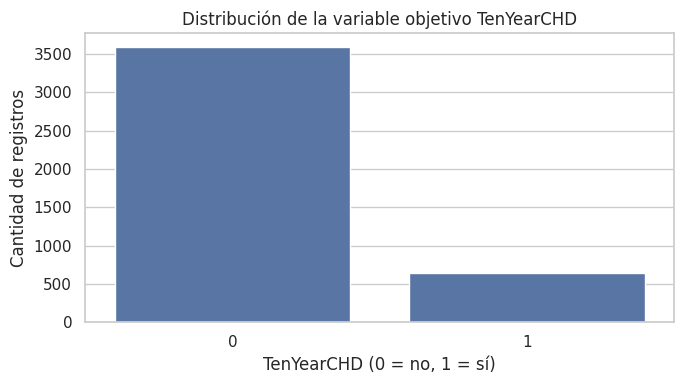

Interpretación: la clase 0 representa 84.81% y la clase 1 representa 15.19% de los registros disponibles.


In [6]:
# Gráfico 1. Distribución de la variable objetivo.
plt.figure(figsize=(7, 4))
ax = sns.countplot(data=df, x="TenYearCHD")
ax.set_title("Distribución de la variable objetivo TenYearCHD")
ax.set_xlabel("TenYearCHD (0 = no, 1 = sí)")
ax.set_ylabel("Cantidad de registros")
plt.tight_layout()
plt.show()

frecuencias = df["TenYearCHD"].value_counts(normalize=True).sort_index() * 100
print("Interpretación: la clase 0 representa "
      f"{frecuencias.get(0, 0):.2f}% y la clase 1 representa "
      f"{frecuencias.get(1, 0):.2f}% de los registros disponibles.")

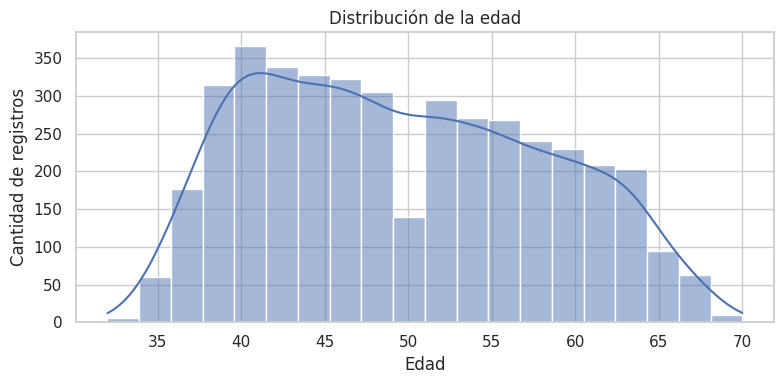

Interpretación: el histograma permite observar en qué edades se concentran los registros.


In [7]:
# Gráfico 2. Distribución de la edad, si la variable está disponible.
if "age" in df.columns:
    plt.figure(figsize=(8, 4))
    sns.histplot(data=df, x="age", bins=20, kde=True)
    plt.title("Distribución de la edad")
    plt.xlabel("Edad")
    plt.ylabel("Cantidad de registros")
    plt.tight_layout()
    plt.show()
    print("Interpretación: el histograma permite observar en qué edades se concentran los registros.")
else:
    print("No se encontró la variable 'age'; se omite este gráfico.")

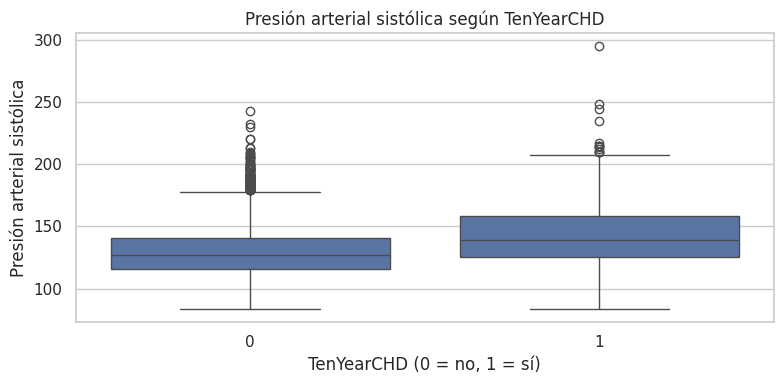

,count,mean,std,min,25%,50%,75%,max
TenYearCHD,,,,,,,,
0,3596.0,130.34,20.45,83.5,116.0,127.0,141.0,243.0
1,644.0,143.62,26.69,83.5,125.0,139.0,158.0,295.0


Interpretación: compara la distribución y la mediana de la presión sistólica entre las dos clases; no demuestra causalidad.


In [8]:
# Gráfico 3. Presión arterial sistólica según la variable objetivo.
if {"sysBP", "TenYearCHD"}.issubset(df.columns):
    plt.figure(figsize=(8, 4))
    sns.boxplot(data=df, x="TenYearCHD", y="sysBP")
    plt.title("Presión arterial sistólica según TenYearCHD")
    plt.xlabel("TenYearCHD (0 = no, 1 = sí)")
    plt.ylabel("Presión arterial sistólica")
    plt.tight_layout()
    plt.show()
    display(df.groupby("TenYearCHD")["sysBP"].describe().round(2))
    print("Interpretación: compara la distribución y la mediana de la presión sistólica entre las dos clases; no demuestra causalidad.")
else:
    print("No se encontraron las columnas necesarias para el gráfico de presión sistólica.")

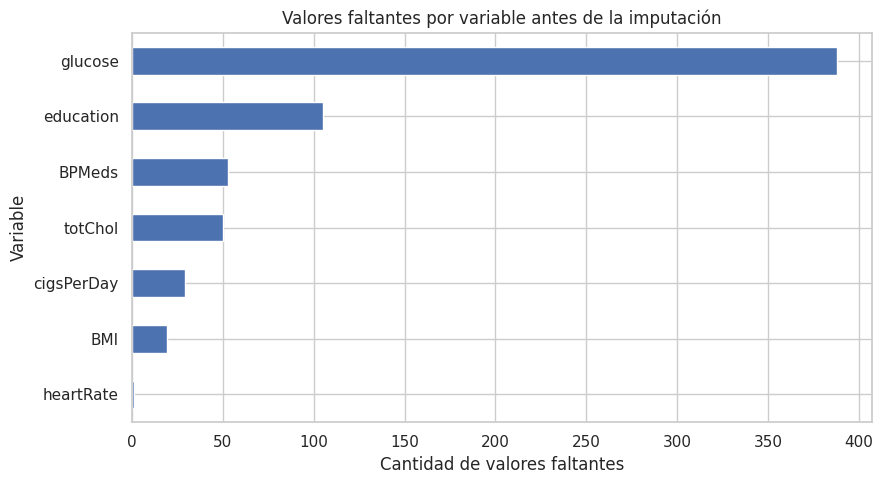

In [9]:
# Gráfico 4. Cantidad de valores faltantes por variable.
faltantes_grafico = df.isna().sum().sort_values(ascending=False)
faltantes_grafico = faltantes_grafico[faltantes_grafico > 0]

if not faltantes_grafico.empty:
    plt.figure(figsize=(9, 5))
    faltantes_grafico.sort_values().plot(kind="barh")
    plt.title("Valores faltantes por variable antes de la imputación")
    plt.xlabel("Cantidad de valores faltantes")
    plt.ylabel("Variable")
    plt.tight_layout()
    plt.show()
else:
    print("No hay valores faltantes en el conjunto actual.")

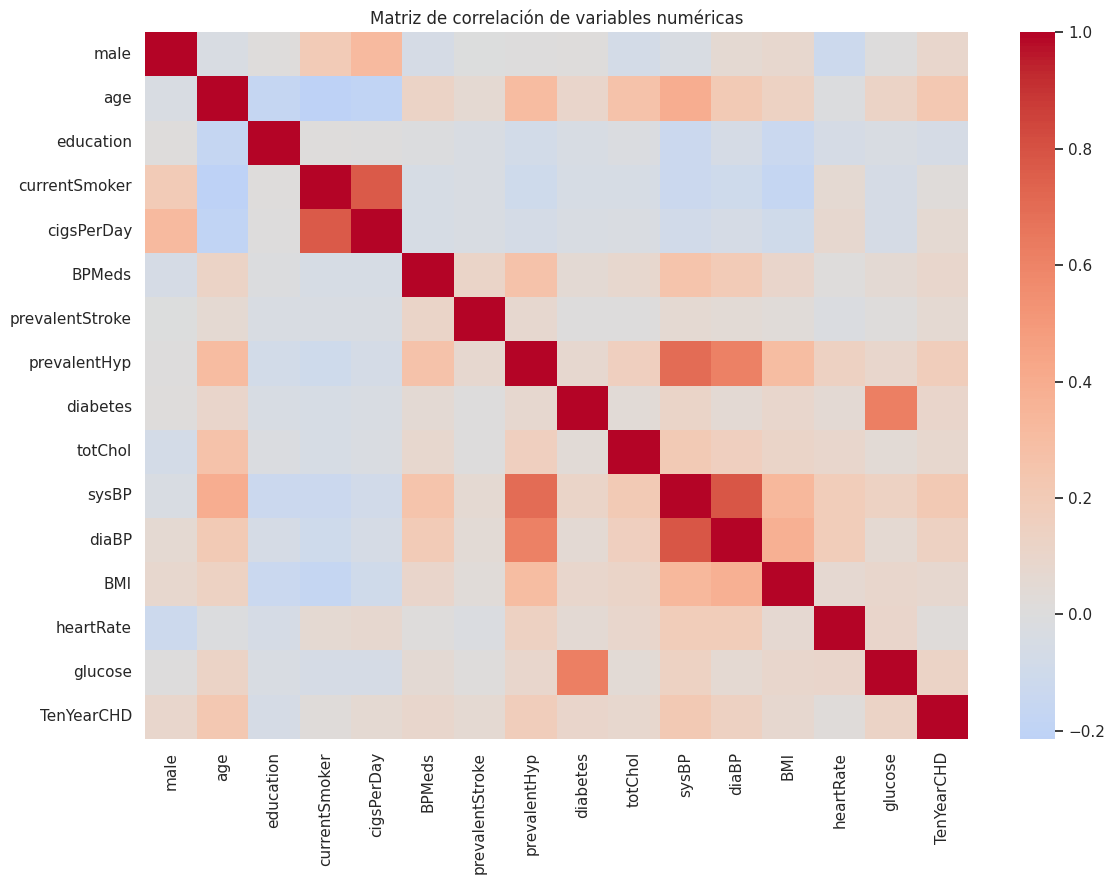

Interpretación: la correlación describe asociaciones lineales entre variables numéricas. No implica que una variable cause cambios en otra.


In [10]:
# Gráfico 5. Correlación entre variables numéricas.
numericas_eda = df.select_dtypes(include=np.number)
if numericas_eda.shape[1] >= 2:
    plt.figure(figsize=(12, 9))
    sns.heatmap(numericas_eda.corr(), cmap="coolwarm", center=0, annot=False)
    plt.title("Matriz de correlación de variables numéricas")
    plt.tight_layout()
    plt.show()
    print("Interpretación: la correlación describe asociaciones lineales entre variables numéricas. "
          "No implica que una variable cause cambios en otra.")
else:
    print("No hay suficientes variables numéricas para calcular correlaciones.")

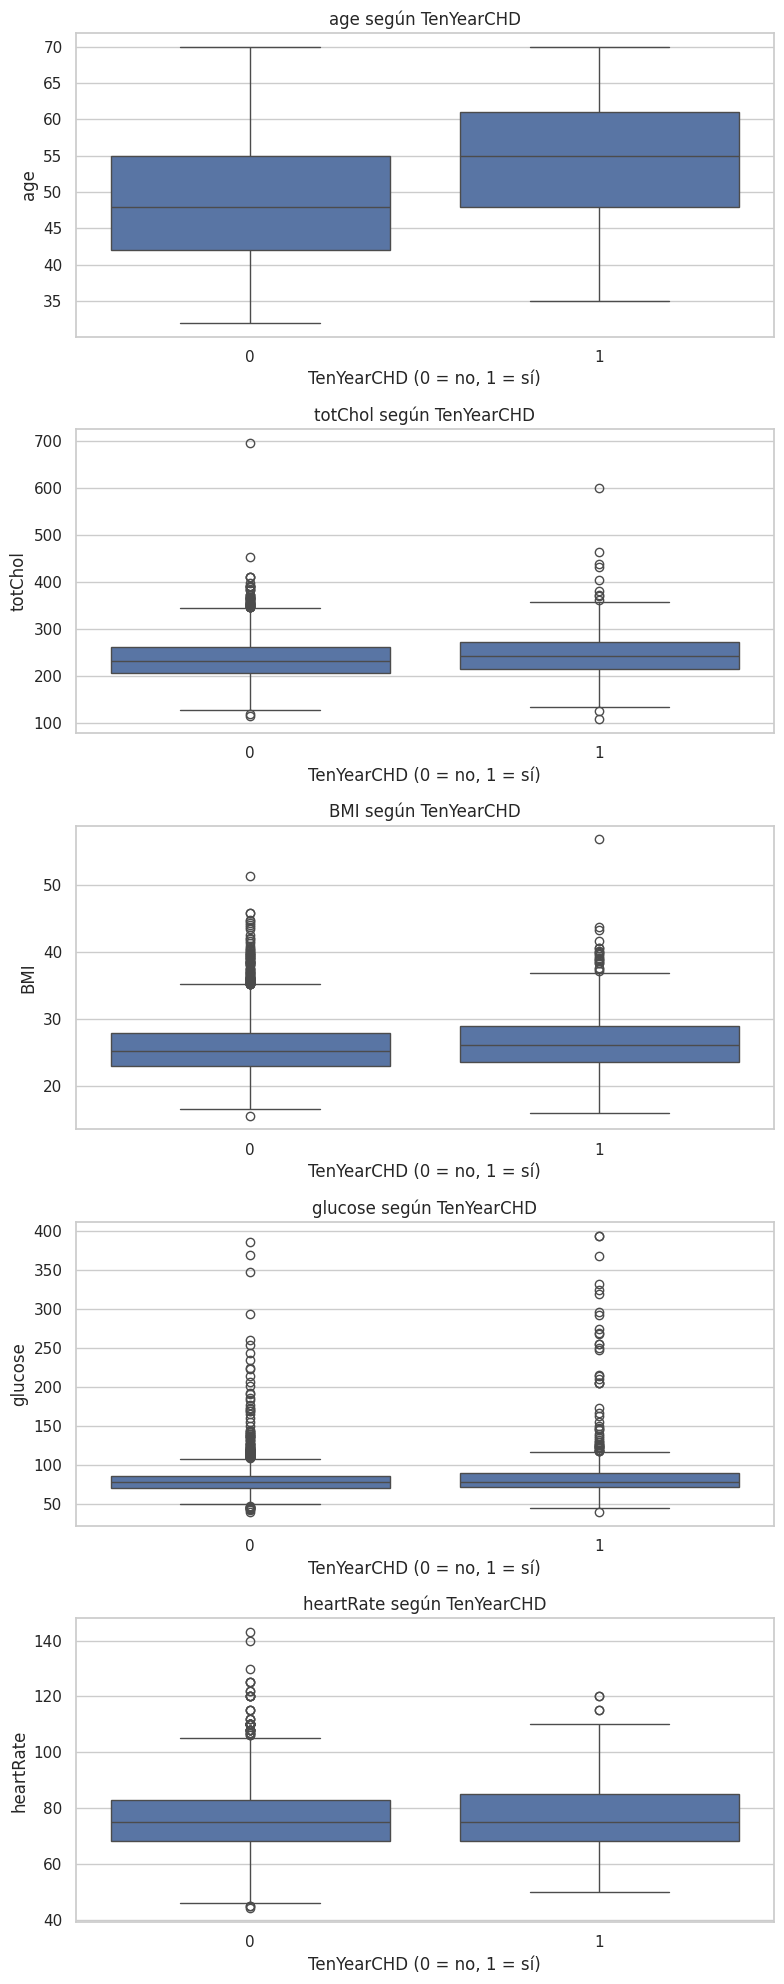

In [11]:
# Gráfico 6. Relación de algunas variables numéricas con la clase objetivo.
variables_grafico = [c for c in ["age", "totChol", "BMI", "glucose", "heartRate"] if c in df.columns]

if variables_grafico:
    fig, axes = plt.subplots(len(variables_grafico), 1, figsize=(8, 4 * len(variables_grafico)))
    if len(variables_grafico) == 1:
        axes = [axes]
    for ax, col in zip(axes, variables_grafico):
        sns.boxplot(data=df, x="TenYearCHD", y=col, ax=ax)
        ax.set_title(f"{col} según TenYearCHD")
        ax.set_xlabel("TenYearCHD (0 = no, 1 = sí)")
        ax.set_ylabel(col)
    plt.tight_layout()
    plt.show()
else:
    print("No se encontraron variables para este gráfico.")

## 7. Preparación para el modelado

Se utilizará `TenYearCHD` como variable objetivo y las demás columnas como variables predictoras, siempre que no sean identificadores ni variables que revelen directamente la respuesta. En el conjunto de datos esperado no se conoce una columna identificadora que deba incluirse.

La variable `education` se tratará como categórica. Las demás variables predictoras se tratarán como numéricas, incluidas las variables binarias codificadas como 0 y 1. Las variables numéricas se imputarán con la mediana y se escalarán para la regresión logística. La variable categórica se imputará con la moda y se codificará mediante one-hot encoding.

La separación entrenamiento/prueba será estratificada para conservar aproximadamente la proporción de clases en ambos conjuntos. La imputación y las transformaciones se ajustarán dentro de cada pipeline usando únicamente los datos de entrenamiento.

In [12]:
X = df.drop(columns=["TenYearCHD"]).copy()
y = df["TenYearCHD"].copy()

# Si education existe, tratarla como categórica; el resto se considera numérico.
columnas_categoricas = [c for c in ["education"] if c in X.columns]
columnas_numericas = [c for c in X.columns if c not in columnas_categoricas]

print("Variables predictoras:", X.shape[1])
print("Variables numéricas:", columnas_numericas)
print("Variables categóricas:", columnas_categoricas)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Registros de entrenamiento:", X_train.shape[0])
print("Registros de prueba:", X_test.shape[0])
print("\nDistribución porcentual de la clase objetivo:")
display(pd.DataFrame({
    "Conjunto": ["Completo", "Entrenamiento", "Prueba"],
    "Clase 1 (%)": [
        y.mean() * 100,
        y_train.mean() * 100,
        y_test.mean() * 100
    ]
}).round(2))

Variables predictoras: 15
Variables numéricas: ['male', 'age', 'currentSmoker', 'cigsPerDay', 'BPMeds', 'prevalentStroke', 'prevalentHyp', 'diabetes', 'totChol', 'sysBP', 'diaBP', 'BMI', 'heartRate', 'glucose']
Variables categóricas: ['education']
Registros de entrenamiento: 3392
Registros de prueba: 848

Distribución porcentual de la clase objetivo:


,Conjunto,Clase 1 (%)
0,Completo,15.19
1,Entrenamiento,15.18
2,Prueba,15.21


### 7.1. Crear los transformadores

El mismo procedimiento de preparación se reutilizará en ambos modelos. Esto hace que la comparación sea más justa y permite ejecutar el flujo completo de forma reproducible.

In [13]:
transformador_numerico = Pipeline(steps=[
    ("imputacion", SimpleImputer(strategy="median")),
    ("escalado", StandardScaler())
])

transformador_categorico = Pipeline(steps=[
    ("imputacion", SimpleImputer(strategy="most_frequent")),
    ("codificacion", OneHotEncoder(handle_unknown="ignore"))
])

transformadores = []
if columnas_numericas:
    transformadores.append(("numericas", transformador_numerico, columnas_numericas))
if columnas_categoricas:
    transformadores.append(("categoricas", transformador_categorico, columnas_categoricas))

preparacion = ColumnTransformer(transformers=transformadores, remainder="drop")

## 8. Entrenamiento de modelos

Se compararán dos modelos:

1. **Regresión logística:** modelo de clasificación que estima la probabilidad de pertenecer a una clase. Se incluye como referencia inicial y se beneficia del escalamiento de variables numéricas.
2. **Árbol de decisión:** modelo que realiza divisiones sucesivas de los datos según las variables predictoras. Puede representar relaciones no lineales, aunque puede sobreajustarse si crece demasiado.

No se realizará optimización de hiperparámetros en este avance, de acuerdo con la guía. Se utilizará la misma división de entrenamiento y prueba para ambos modelos.

In [14]:
modelos = {
    "Regresión logística": LogisticRegression(
        max_iter=2000,
        class_weight=None,
        random_state=RANDOM_STATE
    ),
    "Árbol de decisión": DecisionTreeClassifier(
        random_state=RANDOM_STATE,
        class_weight=None
    )
}

pipelines = {}
for nombre, modelo in modelos.items():
    pipelines[nombre] = Pipeline(steps=[
        ("preparacion", preparacion),
        ("modelo", modelo)
    ])
    pipelines[nombre].fit(X_train, y_train)
    print(f"{nombre}: entrenamiento completado.")

Regresión logística: entrenamiento completado.
Árbol de decisión: entrenamiento completado.


## 9. Evaluación de los modelos

Se calcularán accuracy, precision, recall y F1-score para la clase positiva (`TenYearCHD = 1`). Además, se mostrará el reporte completo por clase y la matriz de confusión.

- **Accuracy:** proporción total de predicciones correctas.
- **Precision de clase 1:** proporción de predicciones positivas que fueron correctas.
- **Recall de clase 1:** proporción de positivos reales que el modelo logró identificar.
- **F1-score de clase 1:** equilibrio entre precision y recall.

Debido al desbalance de clases, las métricas de la clase 1 son especialmente importantes. Los resultados deben interpretarse en conjunto.

In [15]:
resultados = []
predicciones = {}

for nombre, pipeline in pipelines.items():
    y_pred = pipeline.predict(X_test)
    predicciones[nombre] = y_pred

    resultados.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision clase 1": precision_score(y_test, y_pred, pos_label=1, zero_division=0),
        "Recall clase 1": recall_score(y_test, y_pred, pos_label=1, zero_division=0),
        "F1-score clase 1": f1_score(y_test, y_pred, pos_label=1, zero_division=0)
    })

    print(f"\nReporte de clasificación: {nombre}")
    print(classification_report(
        y_test, y_pred,
        labels=[0, 1],
        target_names=["Clase 0", "Clase 1"],
        zero_division=0
    ))

tabla_resultados = pd.DataFrame(resultados).set_index("Modelo").sort_values(
    by="F1-score clase 1", ascending=False
)
display(tabla_resultados.round(4))


Reporte de clasificación: Regresión logística
              precision    recall  f1-score   support

     Clase 0       0.85      0.99      0.91       719
     Clase 1       0.38      0.05      0.08       129

    accuracy                           0.84       848
   macro avg       0.61      0.52      0.50       848
weighted avg       0.78      0.84      0.79       848


Reporte de clasificación: Árbol de decisión
              precision    recall  f1-score   support

     Clase 0       0.86      0.86      0.86       719
     Clase 1       0.22      0.22      0.22       129

    accuracy                           0.76       848
   macro avg       0.54      0.54      0.54       848
weighted avg       0.76      0.76      0.76       848



,Accuracy,Precision clase 1,Recall clase 1,F1-score clase 1
Modelo,,,,
Árbol de decisión,0.7630,0.2188,0.2171,0.2179
Regresión logística,0.8432,0.3750,0.0465,0.0828


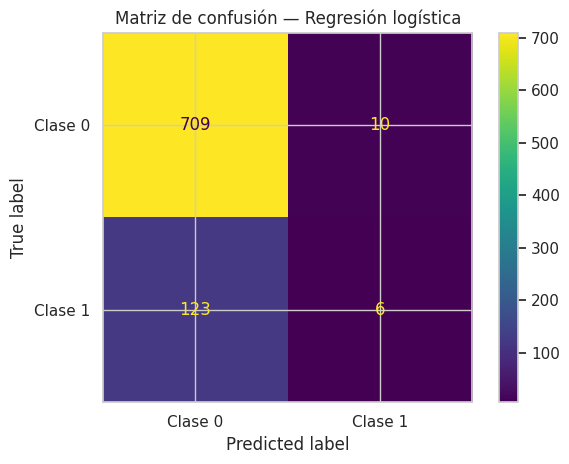

Regresión logística:
  Verdaderos negativos (TN): 709
  Falsos positivos (FP): 10
  Falsos negativos (FN): 123
  Verdaderos positivos (TP): 6
  Los falsos negativos son casos positivos reales que el modelo clasificó como clase 0.


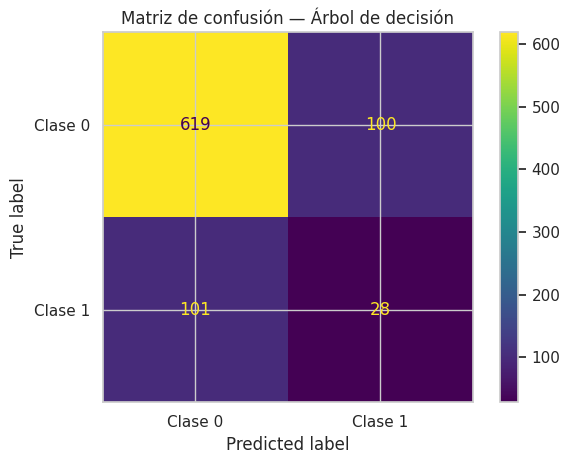

Árbol de decisión:
  Verdaderos negativos (TN): 619
  Falsos positivos (FP): 100
  Falsos negativos (FN): 101
  Verdaderos positivos (TP): 28
  Los falsos negativos son casos positivos reales que el modelo clasificó como clase 0.


In [16]:
# Matrices de confusión para ambos modelos.
for nombre, y_pred in predicciones.items():
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Clase 0", "Clase 1"]
    )
    disp.plot(values_format="d")
    plt.title(f"Matriz de confusión — {nombre}")
    plt.tight_layout()
    plt.show()

    tn, fp, fn, tp = cm.ravel()
    print(f"{nombre}:")
    print(f"  Verdaderos negativos (TN): {tn}")
    print(f"  Falsos positivos (FP): {fp}")
    print(f"  Falsos negativos (FN): {fn}")
    print(f"  Verdaderos positivos (TP): {tp}")
    print("  Los falsos negativos son casos positivos reales que el modelo clasificó como clase 0.")

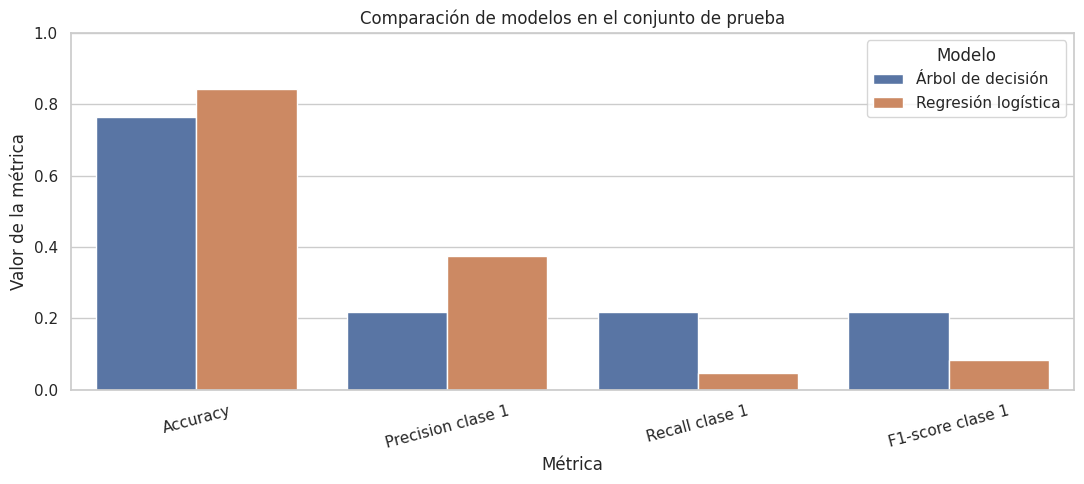

In [17]:
# Comparación visual de las métricas.
tabla_grafico = tabla_resultados.reset_index().melt(
    id_vars="Modelo",
    var_name="Métrica",
    value_name="Valor"
)

plt.figure(figsize=(11, 5))
sns.barplot(data=tabla_grafico, x="Métrica", y="Valor", hue="Modelo")
plt.title("Comparación de modelos en el conjunto de prueba")
plt.ylim(0, 1)
plt.ylabel("Valor de la métrica")
plt.xlabel("Métrica")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 10. Interpretación de resultados

La siguiente celda genera una comparación basada en las métricas calculadas en la ejecución. La selección del modelo no debe basarse únicamente en accuracy: hay que considerar el recall y el F1-score de la clase 1, así como los falsos negativos observados en la matriz de confusión.

El modelo que aparece primero en la tabla está ordenado por F1-score de la clase 1. Esto lo convierte en una referencia para discutir los resultados, pero no determina automáticamente que sea el mejor para cualquier uso.

In [18]:
print("Comparación de métricas:")
display(tabla_resultados.round(4))

modelo_mayor_f1 = tabla_resultados["F1-score clase 1"].idxmax()
print(f"Modelo con mayor F1-score de la clase 1 en esta ejecución: {modelo_mayor_f1}")

print("\nInterpretación orientativa:")
print("- Revisa el recall de la clase 1 para conocer la proporción de casos positivos detectados.")
print("- Revisa precision de la clase 1 para conocer cuántas predicciones positivas fueron correctas.")
print("- Revisa la matriz de confusión para comparar falsos positivos y falsos negativos.")
print("- No interpretes estos resultados como evidencia de validez clínica.")

Comparación de métricas:


,Accuracy,Precision clase 1,Recall clase 1,F1-score clase 1
Modelo,,,,
Árbol de decisión,0.7630,0.2188,0.2171,0.2179
Regresión logística,0.8432,0.3750,0.0465,0.0828


Modelo con mayor F1-score de la clase 1 en esta ejecución: Árbol de decisión

Interpretación orientativa:
- Revisa el recall de la clase 1 para conocer la proporción de casos positivos detectados.
- Revisa precision de la clase 1 para conocer cuántas predicciones positivas fueron correctas.
- Revisa la matriz de confusión para comparar falsos positivos y falsos negativos.
- No interpretes estos resultados como evidencia de validez clínica.


## 11. Limitaciones

- El conjunto de datos presenta desbalance entre las clases.
- Los resultados dependen de los registros disponibles, de la preparación y de la división entrenamiento/prueba.
- En este avance no se realiza búsqueda de hiperparámetros ni validación cruzada.
- Los modelos se evalúan con una única división estratificada; por tanto, sus métricas pueden variar con otra división.
- Las asociaciones observadas en el EDA no demuestran causalidad.
- Este ejercicio académico no sustituye una evaluación médica ni constituye un sistema clínico validado.

## 12. Conclusiones preliminares

Las conclusiones definitivas deben escribirse después de ejecutar todas las celdas. Utiliza la tabla de métricas, los reportes de clasificación y las matrices de confusión para completar los siguientes puntos:

1. **Hallazgos del EDA:** describe las distribuciones y relaciones que efectivamente observaste.
2. **Preparación:** indica cuántos registros quedaron después de la limpieza y cómo se trataron los valores faltantes.
3. **Comparación de modelos:** compara las métricas de ambos modelos, especialmente el recall y F1-score de la clase 1.
4. **Errores relevantes:** explica los falsos negativos y falsos positivos que aparecen en las matrices de confusión.
5. **Trabajo pendiente:** considera evaluar estabilidad con validación cruzada, revisar otras técnicas y mejorar la interpretación de los resultados en el siguiente avance.

No copies conclusiones genéricas si contradicen las salidas que produjo tu ejecución.

## 13. Declaración y evaluación del uso de inteligencia artificial

Completa esta sección según el uso real que haya hecho el grupo. Si se utilizó una IA para ayudar a construir o revisar este notebook, registra la herramienta, el propósito, los prompts relevantes, los errores encontrados, los ajustes realizados y las decisiones finales. No declares que se validó una salida si no se comprobó.

**Plantilla para completar:**

- **Herramienta utilizada:** [nombre de la herramienta/modelo].
- **Propósito:** apoyo para estructurar el notebook, explicar código y revisar el proceso de clasificación.
- **Prompt utilizado:** [copiar el prompt real utilizado].
- **Problemas identificados:** [anotar errores, código que no funcionó, supuestos incorrectos o contenido no respaldado].
- **Ajustes realizados:** [describir las correcciones efectuadas por el grupo].
- **Decisión final:** [explicar qué se conservó y cómo se verificó].

### Declaración de responsabilidad

Como integrantes del grupo, declaramos que revisamos y verificamos el contenido elaborado con apoyo de herramientas de inteligencia artificial. Comprendemos el código, comprobamos que las variables pertenecen al conjunto de datos y verificamos que las métricas y conclusiones coincidan con la ejecución. Asumimos la responsabilidad académica por el notebook y sus resultados.

**Importante:** conserva esta declaración solo si describe fielmente lo que hizo el grupo; de lo contrario, modifícala para reflejar el proceso real.

## 14. Referencias técnicas

- Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.
- McKinney, W. (2010). Data Structures for Statistical Computing in Python. *Proceedings of the 9th Python in Science Conference*, 56–61.

Las referencias técnicas no sustituyen las referencias académicas del estado del arte incluidas en el informe PDF.